In [1]:
import sqlite3
import pandas as pd

# 连接SQLite
conn = sqlite3.connect("ppc_ad.db")

#读取ppc数据集
df_raw = pd.read_excel("ppc_data.xlsx")

#重命名为我们项目统一字段（方便后续代码复用）
df_raw = df_raw.rename(columns={
    "Campaign ID":"campaign_id",
    "Platform":"channel",
    "Target_Age":"audience_segment",
    "Spend":"spend",
    "Impressions":"impressions",
    "Clicks":"clicks",
    "Conversions":"conversions",
    "Revenue":"revenue",
    "Date":"event_date"
})

#写入sqlite数据库
df_raw.to_sql("ad_campaign", conn, index=False, if_exists="replace")

# ========== 本项目实际运行：单表SQL聚合，计算CTR/CVR/CAC/ROI ==========
sql_single = """
SELECT
    campaign_id,
    channel,
    audience_segment,
    event_date,
    spend,
    impressions,
    clicks,
    conversions,
    revenue,
    ROUND(1.0 * clicks / impressions, 4) AS ctr,
    ROUND(CASE WHEN conversions>0 THEN 1.0*conversions / clicks ELSE 0 END,4) AS cvr,
    ROUND(CASE WHEN conversions>0 THEN 1.0*spend / conversions ELSE NULL END,2) AS cac,
    ROUND(CASE WHEN spend>0 THEN 1.0*revenue / spend ELSE NULL END,2) AS roi
FROM ad_campaign
WHERE spend > 0 AND impressions > 0;
"""

agg_df = pd.read_sql(sql_single, conn)
agg_df.to_csv("ad_agg.csv", index=False)

# ---------------- 保留生产环境双表JOIN版本SQL ----------------
"""
-- 生产环境：真实业务两张表JOIN（公开数据集无法运行，作为示例保留）
WITH camp_agg AS (
SELECT
    ac.channel, ac.audience_segment, ac.event_date,
    SUM(ac.spend) AS total_spend,
    SUM(ac.impressions) AS total_imp,
    SUM(ac.clicks) AS total_click,
    SUM(COALESCE(c.revenue,0)) AS total_revenue,
    COUNT(c.user_id) AS convert_cnt
FROM ad_campaign ac
LEFT JOIN conversion c ON ac.campaign_id = c.campaign_id
WHERE ac.spend>0 AND ac.impressions>0
GROUP BY ac.channel, ac.audience_segment, ac.event_date
)
SELECT *,
ROUND(1.0*total_click/total_imp,4) AS ctr
FROM camp_agg;
"""

conn.close()
agg_df.head()


,Campaign_ID,channel,audience_segment,event_date,spend,impressions,clicks,conversions,revenue,ctr,cvr,cac,roi
0,C3578,Instagram,35-44,2025-01-19,6453.9,8698,401,174,27840,0.0461,0.4339,37.09,4.31
1,C6702,LinkedIn,55+,2025-01-22,10067.4,4496,1286,821,128076,0.2860,0.6384,12.26,12.72
2,C9725,Instagram,35-44,2024-07-23,7623.0,7935,1684,1060,193980,0.2122,0.6295,7.19,25.45
3,C9472,Google,25-34,2024-04-20,8504.2,4620,444,308,24024,0.0961,0.6937,27.61,2.82
4,C7601,Google,25-34,2024-08-07,8046.5,5235,1912,1428,277032,0.3652,0.7469,5.63,34.43


Matplotlib is building the font cache; this may take a moment.


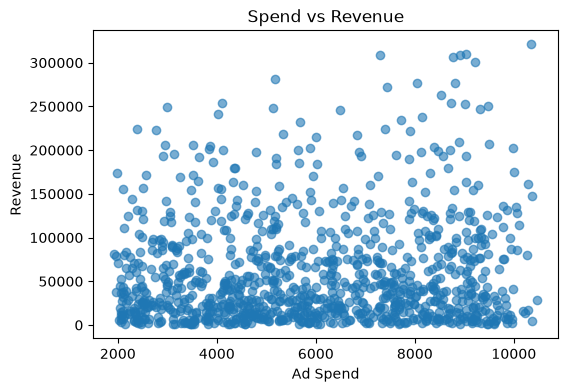

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ad_agg.csv")
df["event_date"] = pd.to_datetime(df["event_date"])
df["month"] = df["event_date"].dt.to_period("M")

#1.各渠道指标对比
channel_summary = df.groupby("channel")[["roi","cac","ctr","cvr","spend","revenue"]].mean().reset_index()

#2.渠道+人群交叉效果
channel_aud = df.groupby(["channel","audience_segment"])["roi"].mean().reset_index()

#3.时间维度看ROI波动
month_roi = df.groupby("month")["roi"].mean()

#4.花费与收益，观察边际收益递减
plt.figure(figsize=(6,4))
plt.scatter(df["spend"], df["revenue"], alpha=0.6)
plt.xlabel("Ad Spend")
plt.ylabel("Revenue")
plt.title("Spend vs Revenue")
plt.show()

随着广告花费（Ad Spend）提升，营收（Revenue）整体呈上升趋势，说明投放预算增加能够带动业务收入增长，广告投放具备正向收益基础。
在低花费区间，营收分布相对集中；当花费持续走高，散点纵向发散程度明显变大。
相同预算增量，高花费区间带来的营收增量不再稳定，上限逐步显现。印证广告投放普遍规律：持续加码预算后，优质流量枯竭，竞价成本抬升，边际回报逐步下滑。
即便在相同投放金额下，营收结果差异巨大。说明除预算规模外，渠道、人群、投放时段、素材等因素显著影响转化效果。

In [3]:
channel_summary

,channel,roi,cac,ctr,cvr,spend,revenue
0,Facebook,13.037222,44.322071,0.270367,0.529019,6230.579798,69929.348485
1,Google,11.577158,36.654809,0.263751,0.512169,5984.766120,62398.666667
2,Instagram,10.811500,39.718200,0.248448,0.520432,5803.116000,55315.575000
3,LinkedIn,11.852723,42.256920,0.249594,0.482906,6015.707589,59940.892857
4,YouTube,11.137846,40.826410,0.261844,0.500507,5739.277436,51958.297436


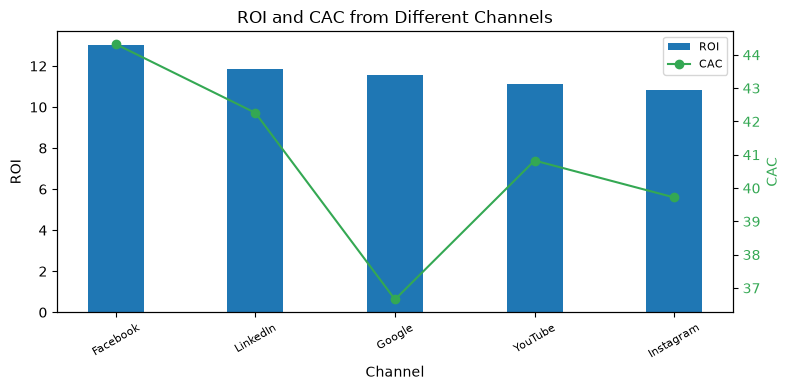

In [4]:
plt.figure(figsize=(8, 4))
df_plot = channel_summary.sort_values("roi", ascending=False)
x = range(len(df_plot["channel"]))
channels = df_plot["channel"].tolist()
roi_data = df_plot["roi"]
cac_data = df_plot["cac"]

ax1 = plt.gca()
bar1 = ax1.bar(x, roi_data, width=0.4, label="ROI")
ax1.set_xlabel("Channel")
ax1.set_ylabel("ROI")
ax1.set_xticks(x)
ax1.set_xticklabels(channels, rotation=30, fontsize=8)
ax1.tick_params(axis="y")

# 第二根Y轴
ax2 = ax1.twinx()
line2 = ax2.plot(x, cac_data, marker="o", color="#34A853", label="CAC")
ax2.set_ylabel("CAC", color="#34A853")
ax2.tick_params(axis="y", labelcolor="#34A853")

plt.title("ROI and CAC from Different Channels")
# 合并图例
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

- Facebook 拥有最高 ROI，但同时CAC 获客成本最高；
- Google ROI 排名中游，却拥有最低CAC。
说明单纯依靠 ROI 高低分配预算存在缺陷：高回报渠道往往伴随更高流量成本，持续扩量更容易出现边际收益下滑。仅依靠渠道维度无法完成精细化预算决策，需要进一步拆解「渠道 + 人群」交叉维度效果。
我们可以用 CTR 和 CVR 把投放链路拆成两段看：曝光→点击、点击→下单。
Facebook 两头数据都最好，广告吸睛、进来也愿意买，但是获客成本最贵。Instagram 恰恰相反，用户点进来之后转化不错，但是广告很难吸引点击，优化重点是素材。LinkedIn 能吸引点击，但是下单转化率最低，流量精准度不足。Google 整条链路均衡，拿用户最便宜，适合扩量。
同时平均值会掩盖人群差异，所以接下来进一步拆分渠道和人群组合

In [5]:
channel_aud

,channel,audience_segment,roi
0,Facebook,18-24,12.922326
1,Facebook,25-34,14.271714
2,Facebook,35-44,10.168462
3,Facebook,45-54,12.977750
4,Facebook,55+,14.890732
5,Google,18-24,12.180571
6,Google,25-34,10.364048
7,Google,35-44,13.655641
8,Google,45-54,8.582286
9,Google,55+,13.251875


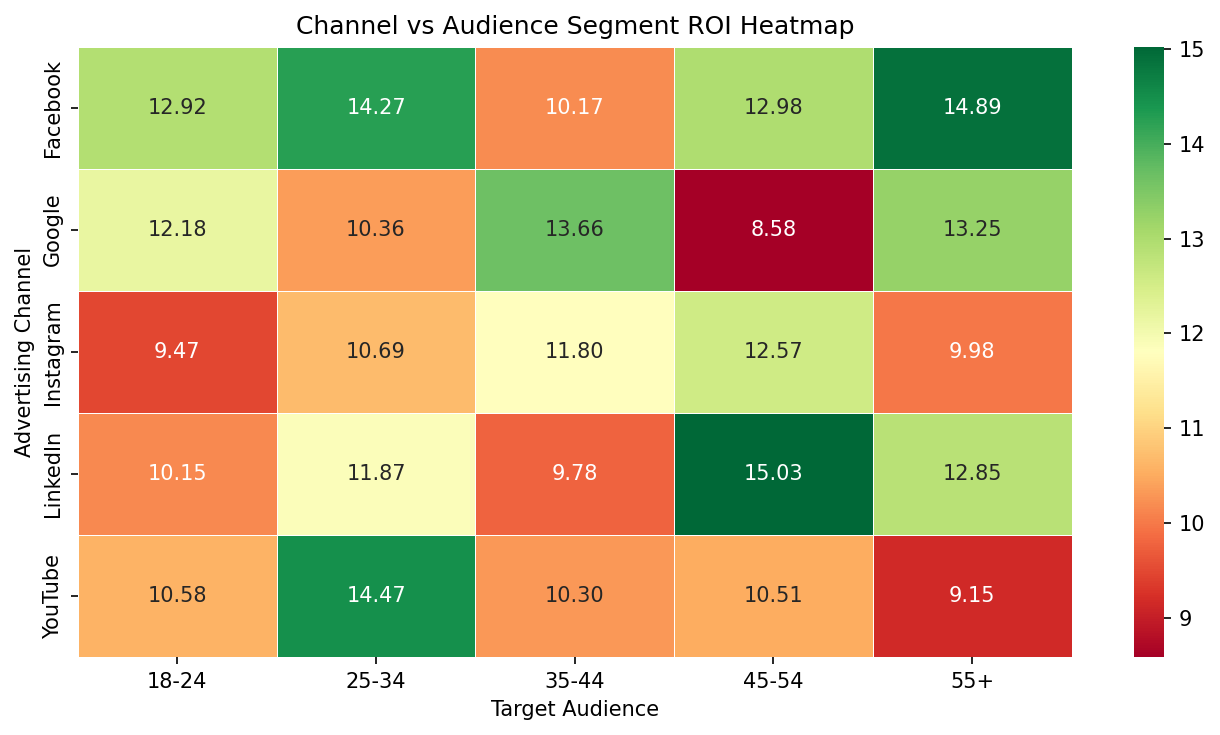

In [20]:
plt.rcParams['figure.dpi'] = 150
# 数据透视：行=渠道，列=人群，值=ROI
pivot_roi = channel_aud.pivot(index="channel", columns="audience_segment", values="roi")

plt.figure(figsize=(9,5))
sns.heatmap(pivot_roi, annot=True, fmt=".2f", cmap="RdYlGn", linewidths=0.4)
plt.title("Channel vs Audience Segment ROI Heatmap")
plt.xlabel("Target Audience")
plt.ylabel("Advertising Channel")
plt.tight_layout()
plt.show()

通过渠道与人群交叉分析，我发现一个很关键的现象：渠道平均效果掩盖了内部巨大差异。
LinkedIn 整体转化率不高，但它 45-54 岁人群拥有全数据集最高 ROI；YouTube 只在 25-34 岁人群表现优秀，其余年龄段收益一般。同时不少渠道存在明显低效人群，比如 Google 的 45-54 年龄段 ROI 不足 9。
这说明预算分配最小单元不能是渠道，必须精确到渠道 + 人群组合。这也为后面三套预算方案对比提供了业务依据，不能简单把钱全部给到整体最好的 Facebook。

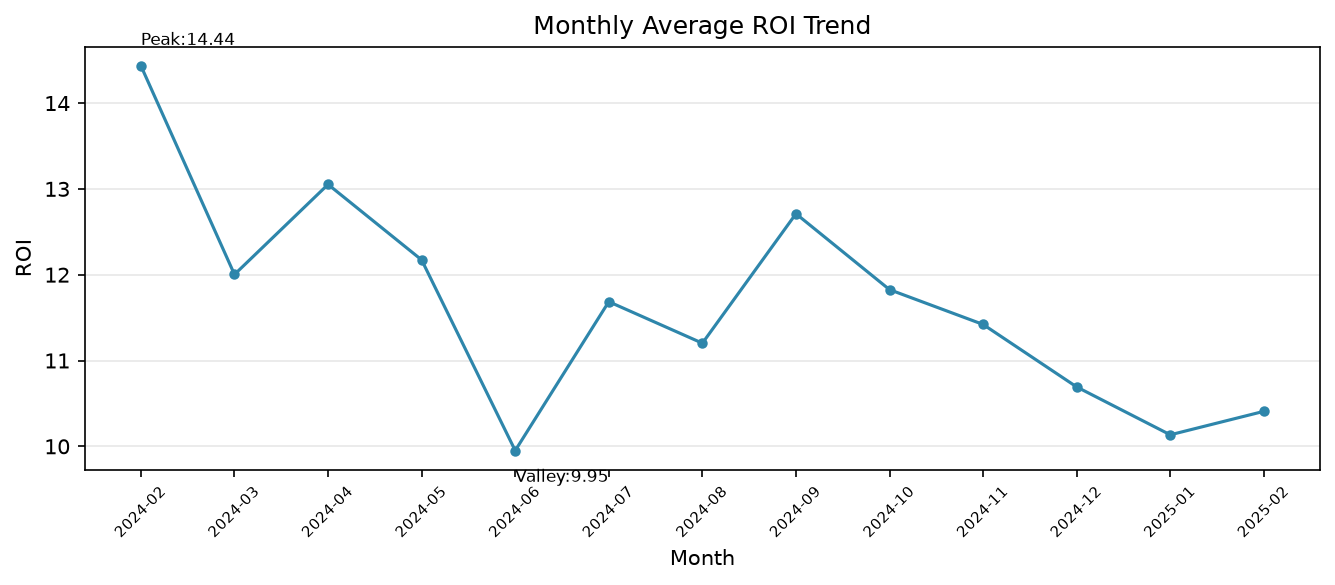

In [6]:
# 1. 正确分组，转为DataFrame，同时把Period转为字符串
month_roi = df.groupby("month")[["roi"]].mean().reset_index()

# 关键：把Period类型的month转为普通字符串 "2024-02"
month_roi["month"] = month_roi["month"].astype(str)

# 2. 绘图代码
plt.rcParams['figure.dpi'] = 150

plt.figure(figsize=(9,4))
plt.plot(month_roi["month"], month_roi["roi"], marker='o', color="#2E86AB", linewidth=1.5, markersize=4)

max_row = month_roi.loc[month_roi["roi"].idxmax()]
min_row = month_roi.loc[month_roi["roi"].idxmin()]
plt.annotate(f'Peak:{max_row["roi"]:.2f}',
             xy=(max_row["month"], max_row["roi"]),
             xytext=(0,10), textcoords="offset points", fontsize=8)
plt.annotate(f'Valley:{min_row["roi"]:.2f}',
             xy=(min_row["month"], min_row["roi"]),
             xytext=(0,-15), textcoords="offset points", fontsize=8)

plt.title("Monthly Average ROI Trend")
plt.xlabel("Month")
plt.ylabel("ROI")
plt.xticks(rotation=45, fontsize=7)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


整体投放收益呈现震荡回落趋势。周期起点 2024-02 达到全时段峰值 ROI=14.44；到周期末尾 2025-01 跌至 10.41。长期收益持续承压，大概率来自行业竞争加剧、平台竞价成本抬升、优质流量逐步饱和.
模型训练基于历史数据，早期样本 ROI 普遍更高。如果直接使用模型预测未来投放回报，存在高估收益的风险。因此后续预算优化方案仅作为决策参考，实际投放需要配合线上 A/B 测试持续验证。
广告长期收益自然衰减属于常态，不能静态沿用历史最优预算配比，需要持续监控各【渠道 + 人群】单元收益变化，动态向当前高 ROI 组合倾斜预算。

接下来通过建模预测给定一组特征投放（渠道、人群、投放花费、月份）能带来revenue总收益

In [32]:
import pandas as pd

df = pd.read_csv("ad_agg.csv")
df["event_date"] = pd.to_datetime(df["event_date"])

# ========= 第一步：构造month特征 =========

df["month"] = df["event_date"].dt.month.astype("category")

# 如果后续要转object给LightGBM：后面再 .astype(str)

# ========= 第二步：时序切分 =========
train = df[df["event_date"] < "2025-01-01"].copy()
test  = df[df["event_date"] >= "2025-01-01"].copy()

# ========= 第三步：划分X y =========
feature_cols = ["channel","audience_segment","month","spend"]
target = "revenue"

X_train = train[feature_cols]
y_train = train[target]
X_test  = test[feature_cols]
y_test  = test[target]

# 校验打印，确认特征存在
print("X_train columns:", X_train.columns.tolist())
print("X_train['month'] dtype:", X_train["month"].dtype)


X_train columns: ['channel', 'audience_segment', 'month', 'spend']
X_train['month'] dtype: category


In [33]:
cat_cols = ["channel", "audience_segment", "month"]

for c in cat_cols:
    categories = pd.concat([
        X_train[c],
        X_test[c]
    ]).astype(str).unique()

    X_train[c] = pd.Categorical(
        X_train[c].astype(str),
        categories=categories
    )

    X_test[c] = pd.Categorical(
        X_test[c].astype(str),
        categories=categories
    )

print(X_train.dtypes)
# 输出全部 object 才算合格


channel             category
audience_segment    category
month               category
spend                float64
dtype: object


[I 2026-08-18 13:42:27,970] A new study created in memory with name: no-name-702ae292-64ff-4144-a2e7-06716b220c4b
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-pac

Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[6]	valid_0's rmse: 63166.6
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 56348
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 58232
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[2]	valid_0's rmse: 56303.5
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[7]	valid_0's rmse: 56345.4
Training until validation scores don't improve for 20 rounds


/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'e

Early stopping, best iteration is:
[27]	valid_0's rmse: 63186.3
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 56230.8
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 57839.4
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[6]	valid_0's rmse: 56238.8
Training until validation scores don't improve for 20 rounds


[I 2026-08-18 13:42:28,458] Trial 1 finished with value: 57995.588298150185 and parameters: {'lr': 0.029844972976996002, 'num_leaves': 40, 'max_depth': 6}. Best is trial 1 with value: 57995.588298150185.
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, e

Early stopping, best iteration is:
[40]	valid_0's rmse: 56482.6
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[12]	valid_0's rmse: 63178.7
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 56263
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 57991.9
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[8]	valid_0's rmse: 56394.5
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[20]	valid_0's rmse: 56672.3
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[5]	valid_0's rmse: 63190.4
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 56364.8


... (31 outputs left out)

Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[23]	valid_0's rmse: 63185.4
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 56232.5
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 57848.4
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[3]	valid_0's rmse: 56293.2
Training until validation scores don't improve for 20 rounds


[I 2026-08-18 13:42:32,277] Trial 19 finished with value: 58046.49382845066 and parameters: {'lr': 0.033217745820012926, 'num_leaves': 28, 'max_depth': 8}. Best is trial 1 with value: 57995.588298150185.


Early stopping, best iteration is:
[28]	valid_0's rmse: 56673
最优超参： {'lr': 0.029844972976996002, 'num_leaves': 40, 'max_depth': 6}
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[2]	valid_0's rmse: 57297


/Users/lana/miniconda3/envs/ds_common/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


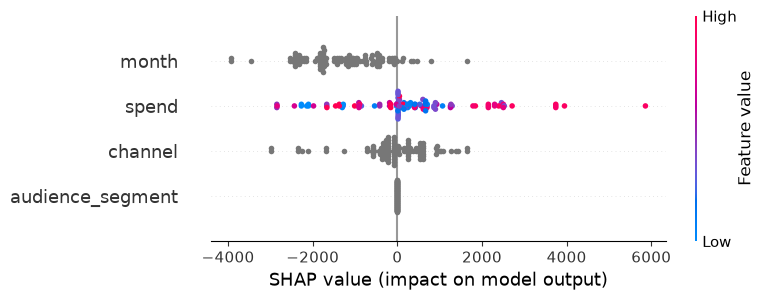

In [34]:
import lightgbm as lgb
import optuna
import shap
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

cat_cols = ["channel","audience_segment","month"]

def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("lr", 0.01, 0.2),
        "num_leaves": trial.suggest_int("num_leaves", 16, 128),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "random_state": 42,
        "objective": "regression",
        "metric": "rmse",
        "verbose": -1
    }
    
    tscv = TimeSeriesSplit(n_splits=5)
    rmse_scores = []
    
    for train_idx, valid_idx in tscv.split(X_train):
        X_tr, X_vl = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        y_tr, y_vl = y_train.iloc[train_idx], y_train.iloc[valid_idx]
        
        reg = lgb.LGBMRegressor(**params)
        reg.fit(
    X_tr,
    y_tr,
    categorical_feature=cat_cols,
    eval_set=[(X_vl, y_vl)],
    callbacks=[
        lgb.early_stopping(20),
        lgb.log_evaluation(0)
    ]
)
        y_pred = reg.predict(X_vl)
        rmse = np.sqrt(
            mean_squared_error(y_vl, y_pred)
        )

        rmse_scores.append(rmse)
        
    return np.mean(rmse_scores)

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)
best_params = study.best_params
print("最优超参：", best_params)

# 用最优参数训练最终模型
final_params = {
    "random_state":42,
    "objective":"regression",
    "metric":"rmse",
    **best_params
}
model = lgb.LGBMRegressor(**final_params, verbose=-1)
model.fit(
    X_train, y_train,
    categorical_feature=cat_cols,
    eval_set=[(X_test, y_test)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=20),
        lgb.log_evaluation(period=0)
    ]
)

# SHAP 分析不变，后续正常看渠道、受众段贡献
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test)


In [ ]:
# SHAP value dataframe
shap_df = pd.DataFrame(
    shap_values.values,
    columns=X_test.columns,
    index=X_test.index
)

# 原始特征 + SHAP
analysis_df = X_test.copy()

analysis_df["channel"] = analysis_df["channel"].astype(str)
analysis_df["audience_segment"] = analysis_df["audience_segment"].astype(str)

analysis_df["channel_shap"] = shap_df["channel"]
analysis_df["month_shap"] = shap_df["month"]
analysis_df["spend_shap"] = shap_df["spend"]

print(analysis_df.head())

      channel audience_segment month    spend  channel_shap   month_shap  \
0   Instagram            35-44     1   6453.9  -1251.376542  -484.860796   
1    LinkedIn              55+     1  10067.4    253.825132 -2528.267556   
25  Instagram            25-34     2   4447.2  -2108.110837  -979.590591   
32   LinkedIn              55+     2   5397.0   1023.335226   374.289925   
52     Google            35-44     1   3029.4   -270.795232 -1713.871148   

    spend_shap  
0  -909.775849  
1  -157.324439  
25 -848.689538  
32  437.676230  
52  311.259908  


In [11]:
#各 Channel 的平均 SHAP value
channel_analysis = (
    analysis_df
    .groupby("channel")["channel_shap"]
    .mean()
    .sort_values()
)

print(channel_analysis)

channel
Instagram   -701.087305
YouTube     -389.196018
Google       -91.543749
LinkedIn     544.312726
Facebook     587.083231
Name: channel_shap, dtype: float64


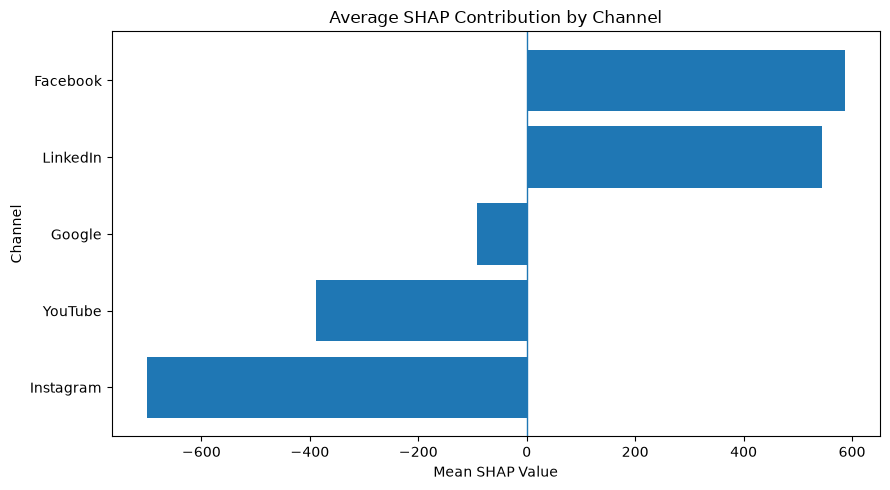

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))

plt.barh(
    channel_analysis.index,
    channel_analysis.values
)

plt.axvline(0, linewidth=1)

plt.xlabel("Mean SHAP Value")
plt.ylabel("Channel")
plt.title("Average SHAP Contribution by Channel")

plt.tight_layout()
plt.show()

In [16]:

month_analysis = (
    analysis_df
    .groupby("month")["month_shap"]
    .mean()
    .sort_values()
)

print(month_analysis)

month
1   -1307.521956
2    -947.836452
Name: month_shap, dtype: float64


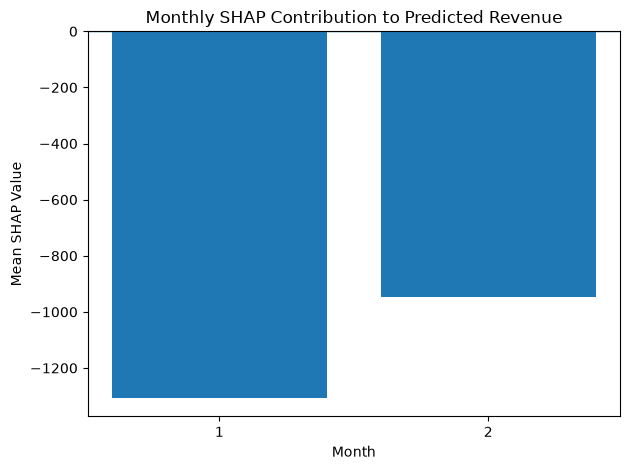

In [19]:


plt.bar(
    month_analysis.index,
    month_analysis.values
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Month")
plt.ylabel("Mean SHAP Value")
plt.title("Monthly SHAP Contribution to Predicted Revenue")


plt.tight_layout()
plt.show()

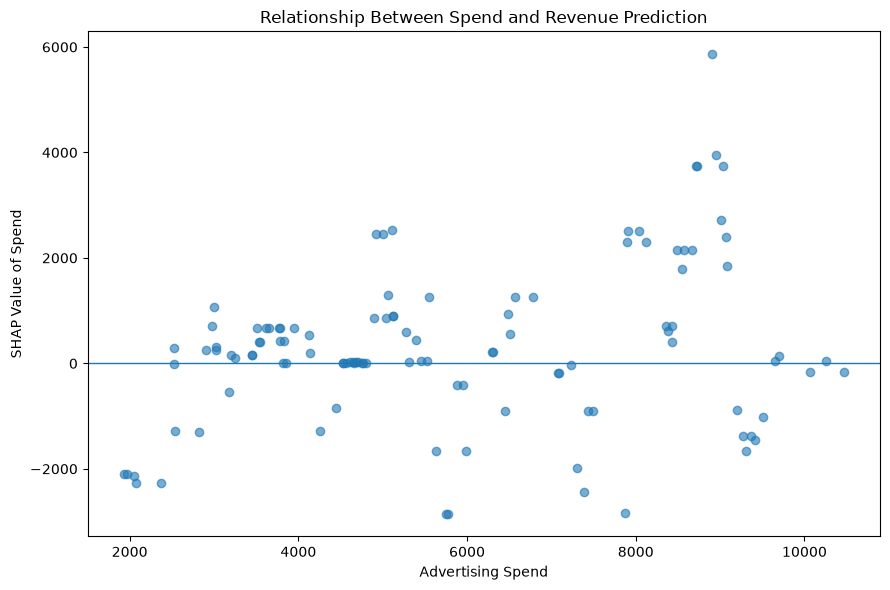

In [20]:
plt.figure(figsize=(9, 6))

plt.scatter(
    analysis_df["spend"],
    analysis_df["spend_shap"],
    alpha=0.6
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Advertising Spend")
plt.ylabel("SHAP Value of Spend")
plt.title("Relationship Between Spend and Revenue Prediction")

plt.tight_layout()
plt.show()

In [62]:
category_levels = {
    c: list(X_train[c].cat.categories)
    for c in ["channel", "audience_segment", "month"]
}

def predict_revenue(channel, audience_segment, month, spend):
    input_df = pd.DataFrame({
        "channel": [str(channel).strip()],
        "audience_segment": [str(audience_segment).strip()],
        "month": [str(month).strip().zfill(2)],
        "spend": [float(spend)]
    })

    # 关键：预测时也用训练时一致的 category levels
    for c in ["channel", "audience_segment", "month"]:
        input_df[c] = pd.Categorical(
            input_df[c].astype(str),
            categories=category_levels[c]
        )

    # 保证列顺序和训练时一致
    input_df = input_df[["channel", "audience_segment", "month", "spend"]]

    return float(model.predict(input_df)[0])

TOTAL_BUDGET = 10000
SCENARIO_MONTH = "05"

candidate_units = (
    df[["channel", "audience_segment"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

n_units = len(candidate_units)
print("候选组合数量:", n_units)

equal_budget = TOTAL_BUDGET / n_units

scheme_A = candidate_units.copy()
scheme_A["budget"] = equal_budget

scheme_A["predicted_revenue"] = scheme_A.apply(
    lambda row: predict_revenue(
        row["channel"],
        row["audience_segment"],
        SCENARIO_MONTH,
        row["budget"]
    ),
    axis=1
)

scheme_A["predicted_roi"] = scheme_A["predicted_revenue"] / scheme_A["budget"]

print("\n===== Scheme A: Equal Allocation =====")
print(scheme_A)

print("\nTotal Budget:", scheme_A["budget"].sum())
print("Total Predicted Revenue:", scheme_A["predicted_revenue"].sum())

候选组合数量: 25

===== Scheme A: Equal Allocation =====
      channel audience_segment  budget  predicted_revenue  predicted_roi
0   Instagram            35-44   400.0       59393.231241     148.483078
1    LinkedIn              55+   400.0       58485.819163     146.214548
2      Google            25-34   400.0       59393.231241     148.483078
3     YouTube            45-54   400.0       59393.231241     148.483078
4   Instagram            25-34   400.0       59393.231241     148.483078
5     YouTube            18-24   400.0       59393.231241     148.483078
6    LinkedIn            25-34   400.0       58485.819163     146.214548
7     YouTube            35-44   400.0       59393.231241     148.483078
8    Facebook              55+   400.0       58485.819163     146.214548
9     YouTube              55+   400.0       59393.231241     148.483078
10     Google              55+   400.0       59393.231241     148.483078
11  Instagram            45-54   400.0       59393.231241     148.483078


/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/478197036.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/478197036.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/478197036.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/478197036.py:16: Pandas4Warning: Constructing a Categorical with a dt

In [47]:
# ============================================
# 3. Historical ROI
# ============================================

historical_roi = (
    df.groupby(["channel", "audience_segment"])
    .agg(
        total_revenue=("revenue", "sum"),
        total_spend=("spend", "sum")
    )
    .reset_index()
)

historical_roi["historical_roi"] = (
    historical_roi["total_revenue"]
    / historical_roi["total_spend"]
)

historical_roi = historical_roi.sort_values(
    "historical_roi",
    ascending=False
)

print("\n===== Historical ROI =====")
print(historical_roi)


===== Historical ROI =====
      channel audience_segment  total_revenue  total_spend  historical_roi
7      Google            35-44        2615731     211445.7       12.370698
4    Facebook              55+        3156854     255969.0       12.332954
1    Facebook            25-34        2758068     227092.1       12.145152
5      Google            18-24        2852787     235975.3       12.089346
18   LinkedIn            45-54        2738491     235733.3       11.616904
19   LinkedIn              55+        3170623     274179.5       11.564041
9      Google              55+        2181911     189654.9       11.504638
3    Facebook            45-54        2777419     248967.2       11.155763
13  Instagram            45-54        2811739     255161.9       11.019431
21    YouTube            25-34        2684882     248673.1       10.796833
0    Facebook            18-24        2928301     274646.6       10.662069
16   LinkedIn            25-34        2889303     286622.6       10.0805

In [48]:
best_unit = historical_roi.iloc[0]

print("\nHistorical ROI Best Unit:")
print("Channel:", best_unit["channel"])
print("Audience:", best_unit["audience_segment"])
print("ROI:", best_unit["historical_roi"])


Historical ROI Best Unit:
Channel: Google
Audience: 35-44
ROI: 12.370698481927038


In [49]:
# ============================================
# 4. Scheme B — Historical ROI Best
# ============================================

scheme_B = candidate_units.copy()

scheme_B["budget"] = 0.0

mask = (
    (scheme_B["channel"] == best_unit["channel"]) &
    (scheme_B["audience_segment"] == best_unit["audience_segment"])
)

scheme_B.loc[mask, "budget"] = TOTAL_BUDGET

scheme_B["predicted_revenue"] = scheme_B.apply(
    lambda row: (
        predict_revenue(
            row["channel"],
            row["audience_segment"],
            SCENARIO_MONTH,
            row["budget"]
        )
        if row["budget"] > 0
        else 0
    ),
    axis=1
)

scheme_B["predicted_roi"] = np.where(
    scheme_B["budget"] > 0,
    scheme_B["predicted_revenue"] / scheme_B["budget"],
    np.nan
)

print("\n===== Scheme B: Historical ROI Best =====")
print(scheme_B)

print("\nTotal Budget:",
      scheme_B["budget"].sum())

print("Total Predicted Revenue:",
      scheme_B["predicted_revenue"].sum())


===== Scheme B: Historical ROI Best =====
      channel audience_segment   budget  predicted_revenue  predicted_roi
0   Instagram            35-44      0.0           0.000000            NaN
1    LinkedIn              55+      0.0           0.000000            NaN
2      Google            25-34      0.0           0.000000            NaN
3     YouTube            45-54      0.0           0.000000            NaN
4   Instagram            25-34      0.0           0.000000            NaN
5     YouTube            18-24      0.0           0.000000            NaN
6    LinkedIn            25-34      0.0           0.000000            NaN
7     YouTube            35-44      0.0           0.000000            NaN
8    Facebook              55+      0.0           0.000000            NaN
9     YouTube              55+      0.0           0.000000            NaN
10     Google              55+      0.0           0.000000            NaN
11  Instagram            45-54      0.0           0.000000           

/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(


In [50]:
# ============================================
# 5. Scheme C — Reference Prediction
# ============================================

reference_budget = TOTAL_BUDGET / n_units

scheme_C = candidate_units.copy()

scheme_C["reference_budget"] = reference_budget

scheme_C["reference_predicted_revenue"] = scheme_C.apply(
    lambda row: predict_revenue(
        row["channel"],
        row["audience_segment"],
        SCENARIO_MONTH,
        reference_budget
    ),
    axis=1
)

print("\n===== Reference Prediction =====")
print(
    scheme_C[
        [
            "channel",
            "audience_segment",
            "reference_budget",
            "reference_predicted_revenue"
        ]
    ]
)


===== Reference Prediction =====
      channel audience_segment  reference_budget  reference_predicted_revenue
0   Instagram            35-44             400.0                 59393.231241
1    LinkedIn              55+             400.0                 58485.819163
2      Google            25-34             400.0                 59393.231241
3     YouTube            45-54             400.0                 59393.231241
4   Instagram            25-34             400.0                 59393.231241
5     YouTube            18-24             400.0                 59393.231241
6    LinkedIn            25-34             400.0                 58485.819163
7     YouTube            35-44             400.0                 59393.231241
8    Facebook              55+             400.0                 58485.819163
9     YouTube              55+             400.0                 59393.231241
10     Google              55+             400.0                 59393.231241
11  Instagram            45-54

/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with 

In [51]:
scheme_C["prediction_weight"] = (
    scheme_C["reference_predicted_revenue"]
    / scheme_C["reference_predicted_revenue"].sum()
)

print(
    scheme_C[
        [
            "channel",
            "audience_segment",
            "reference_predicted_revenue",
            "prediction_weight"
        ]
    ]
)

      channel audience_segment  reference_predicted_revenue  prediction_weight
0   Instagram            35-44                 59393.231241           0.040246
1    LinkedIn              55+                 58485.819163           0.039631
2      Google            25-34                 59393.231241           0.040246
3     YouTube            45-54                 59393.231241           0.040246
4   Instagram            25-34                 59393.231241           0.040246
5     YouTube            18-24                 59393.231241           0.040246
6    LinkedIn            25-34                 58485.819163           0.039631
7     YouTube            35-44                 59393.231241           0.040246
8    Facebook              55+                 58485.819163           0.039631
9     YouTube              55+                 59393.231241           0.040246
10     Google              55+                 59393.231241           0.040246
11  Instagram            45-54                 59393

In [53]:
PERFORMANCE_RATIO = 0.7
DIVERSIFICATION_RATIO = 0.3

performance_budget = (
    TOTAL_BUDGET * PERFORMANCE_RATIO
)

diversification_budget = (
    TOTAL_BUDGET * DIVERSIFICATION_RATIO
)

scheme_C["performance_budget"] = (
    performance_budget
    * scheme_C["prediction_weight"]
)
scheme_C["diversification_budget"] = (
    diversification_budget / n_units
)
scheme_C["budget"] = (
    scheme_C["performance_budget"]
    + scheme_C["diversification_budget"]
)
print(
    "\nTotal Scheme C Budget:",
    scheme_C["budget"].sum()
)


Total Scheme C Budget: 10000.0


In [55]:
scheme_C["predicted_revenue"] = scheme_C.apply(
    lambda row: predict_revenue(
        row["channel"],
        row["audience_segment"],
        SCENARIO_MONTH,
        row["budget"]
    ),
    axis=1
)

scheme_C["predicted_roi"] = (
    scheme_C["predicted_revenue"]
    / scheme_C["budget"]
)

print("\n===== Scheme C =====")

print(
    scheme_C[
        [
            "channel",
            "audience_segment",
            "budget",
            "predicted_revenue",
            "predicted_roi"
        ]
    ].sort_values("budget", ascending=False)
)


===== Scheme C =====
      channel audience_segment      budget  predicted_revenue  predicted_roi
0   Instagram            35-44  401.721662       59393.231241     147.846723
9     YouTube              55+  401.721662       59393.231241     147.846723
22  Instagram              55+  401.721662       59393.231241     147.846723
21    YouTube            25-34  401.721662       59393.231241     147.846723
15     Google            18-24  401.721662       59393.231241     147.846723
13     Google            35-44  401.721662       59393.231241     147.846723
11  Instagram            45-54  401.721662       59393.231241     147.846723
10     Google              55+  401.721662       59393.231241     147.846723
12  Instagram            18-24  401.721662       59393.231241     147.846723
7     YouTube            35-44  401.721662       59393.231241     147.846723
5     YouTube            18-24  401.721662       59393.231241     147.846723
4   Instagram            25-34  401.721662       59393

/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  input_df[c] = pd.Categorical(
/var/folders/zs/qk3sypr10556t7t4q5w3tvym0000gp/T/ipykernel_8004/2011635456.py:17: Pandas4Warning: Constructing a Categorical with 

In [56]:
# ============================================
# 6. Compare A / B / C
# ============================================

summary = pd.DataFrame({
    "Strategy": [
        "A - Equal Allocation",
        "B - Historical ROI Best",
        "C - Model-driven + Diversified"
    ],
    
    "Total Budget": [
        scheme_A["budget"].sum(),
        scheme_B["budget"].sum(),
        scheme_C["budget"].sum()
    ],
    
    "Predicted Revenue": [
        scheme_A["predicted_revenue"].sum(),
        scheme_B["predicted_revenue"].sum(),
        scheme_C["predicted_revenue"].sum()
    ]
})

summary["Predicted ROI"] = (
    summary["Predicted Revenue"]
    / summary["Total Budget"]
)

print("\n================================")
print("Budget Allocation Comparison")
print("================================")

print(summary)


Budget Allocation Comparison
                         Strategy  Total Budget  Predicted Revenue  \
0            A - Equal Allocation       10000.0       1.475757e+06   
1         B - Historical ROI Best       10000.0       5.866403e+04   
2  C - Model-driven + Diversified       10000.0       1.475757e+06   

   Predicted ROI  
0     147.575666  
1       5.866403  
2     147.575666  


In [58]:
print(df[["spend", "revenue"]].describe())
print(
    df[
        ["channel", "audience_segment", "spend", "revenue"]
    ].head(20)
)

              spend        revenue
count   1000.000000    1000.000000
mean    5956.167800   59886.710000
std     2330.082996   60237.650065
min     1928.500000     598.000000
25%     4031.475000   15111.250000
50%     5843.650000   39378.000000
75%     7994.850000   86009.000000
max    10468.500000  320788.000000
      channel audience_segment    spend  revenue
0   Instagram            35-44   6453.9    27840
1    LinkedIn              55+  10067.4   128076
2   Instagram            35-44   7623.0   193980
3      Google            25-34   8504.2    24024
4      Google            25-34   8046.5   277032
5     YouTube            45-54   5177.5    21780
6   Instagram            25-34   4508.4    51528
7     YouTube            18-24   7334.0    71448
8    LinkedIn            25-34   2111.4    15744
9     YouTube            35-44   2628.7     7236
10   Facebook              55+   3500.0    97856
11     Google            25-34   2137.5      598
12    YouTube              55+   7609.2    22792

In [60]:
print(df["month"].unique())

[ 1  7  4  8  5  6 11  9  3  2 10 12]


In [66]:
# 任选一个candidate单元测试
ch = candidate_units["channel"].iloc[0]
seg = candidate_units["audience_segment"].iloc[0]
m = "12"
for b in [400,800,1200]:
    r = predict_revenue(ch, seg, m, b)
    print(f"budget={b}, revenue={r:.2f}, roi={r/b:.2f}")


budget=400, revenue=60111.79, roi=150.28
budget=800, revenue=60111.79, roi=75.14
budget=1200, revenue=60111.79, roi=50.09


In [71]:
# 随便抽取一组相同 channel + audience_segment + month
sample = df[(df["channel"]=="xxx") & (df["audience_segment"]=="xxx") & (df["month"]=="12")]
print(sample[["spend","revenue"]])
print("该组合记录条数：", len(sample))


Empty DataFrame
Columns: [spend, revenue]
Index: []
该组合记录条数： 0


In [73]:
# 随便抽取一组相同 channel + audience_segment + month
sample = df[(df["channel"]=="Google") & (df["audience_segment"]=="35-44") & (df["month"]=="12")]
print(sample[["spend","revenue"]])
print("该组合记录条数：", len(sample))


Empty DataFrame
Columns: [spend, revenue]
Index: []
该组合记录条数： 0
